In [6]:
import matplotlib.pyplot as plt
import numpy as np
import re
import pandas as pd
import csv

In [8]:
headers = ['sim_name', 'alpha', 'beta', 'vd', 'sg', 'D']
PDE_names = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_mean.csv', header=None, names=headers)['sim_name']

In [9]:
def get_n(s):
    match = re.search(r'\d+$', s)
    if match:
        return int(match.group())
    else:
        return None

In [69]:
dalpha = []
dbeta = []
dvd = []
dsg = []
dD = []
ns = []
sim_names = PDE_names.to_list()
for sim in sim_names:
    n = get_n(sim)
    try:
        guess_df = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/fit_data/constantguess/output_fungi_' + str(n) + '_constantguess.csv')[['alpha', 'beta', 'vd', 'sg', 'D']]
        if guess_df.iloc[0]['beta'] <=0:
            guess_df['beta'] = 1e-6
        fit_df = pd.read_csv('/Users/laurenyan/bmxfungi_surrogate/pareto_mean.csv',header=None, names=headers, index_col = 0).loc[['output_fungi_' + str(n)]]
        dalpha.append((guess_df.iloc[0]['alpha'] - fit_df.iloc[0]['alpha']) / guess_df.iloc[0]['alpha'])
        dbeta.append((guess_df.iloc[0]['beta'] - fit_df.iloc[0]['beta']) / guess_df.iloc[0]['beta'])
        dvd.append((guess_df.iloc[0]['vd'] - fit_df.iloc[0]['vd']) / guess_df.iloc[0]['vd'])
        dsg.append((guess_df.iloc[0]['sg'] - fit_df.iloc[0]['sg']) / guess_df.iloc[0]['sg'])
        dD.append((guess_df.iloc[0]['D'] - fit_df.iloc[0]['D']) / guess_df.iloc[0]['D'])
        ns.append(n)
    except FileNotFoundError:
        print(n)

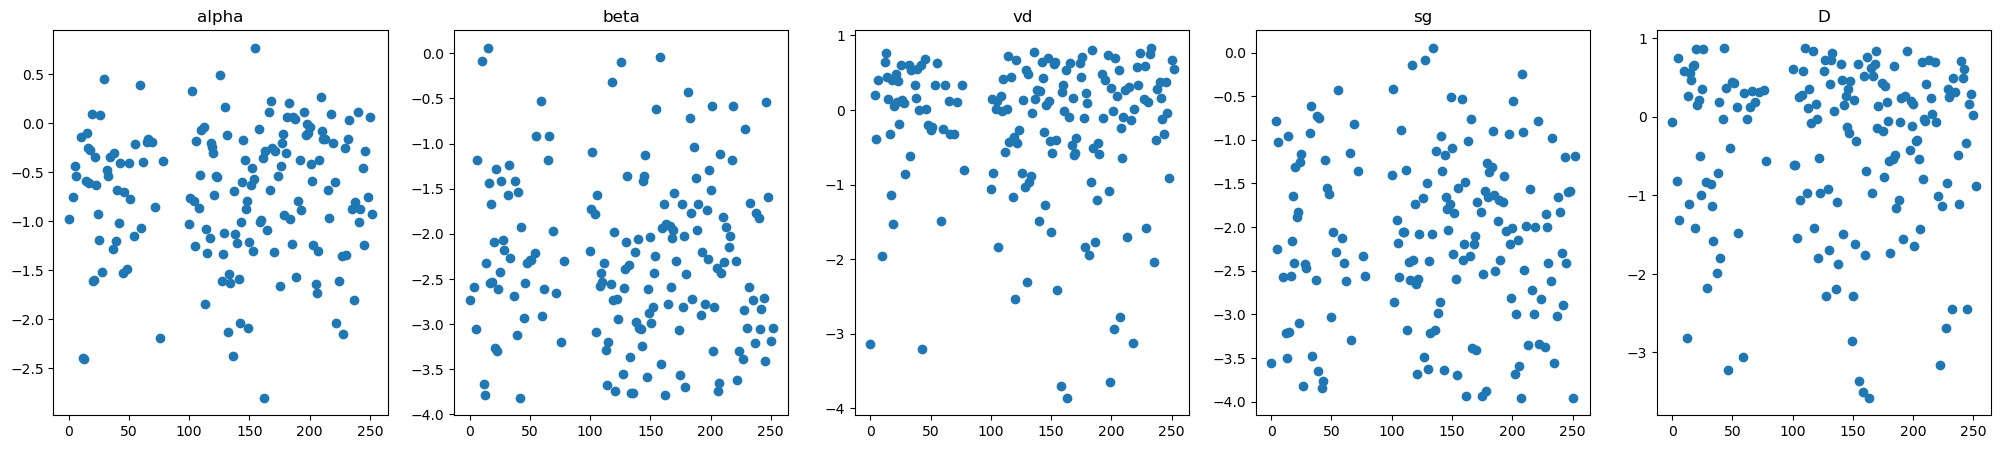

In [70]:
fig, ax = plt.subplots(1, 5, figsize = (25, 5))
dlist = [dalpha, dbeta, dvd, dsg, dD]
names = ['alpha', 'beta', 'vd', 'sg', 'D']
for i in range(5):
    ax[i].scatter(ns, dlist[i])
    ax[i].set_title(names[i])